# Predicción de rotación de personal — Superior Cleaning Services

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/guzmanjmanuel/IA_prediccionDeRotacion/blob/main/notebooks/prediccion_rotacion.ipynb)

**Objetivo:** construir un modelo de Machine Learning que, al cierre de cada mes, estime la probabilidad de que cada colaborador activo **deje la empresa en los próximos 3 meses**, usando únicamente el historial de planillas 2016–2025 (datos anonimizados).

**Contenido**
1. Definición del problema
2. Carga de datos (desde GitHub)
3. Exploración y calidad de datos
4. Construcción del dataset analítico (variables y target)
5. Preprocesamiento
6. Iteración 1 — Regresión logística (línea base)
7. Iteración 2 — Gradient Boosting + variables ampliadas + ajuste de hiperparámetros
8. Comparación, interpretación y lista de riesgo
9. Respuestas a las preguntas de análisis

## 1. Definición del problema

### Contexto organizacional
**Superior Cleaning Services** es una empresa salvadoreña de servicios de limpieza que coloca personal operativo en las instalaciones de sus clientes. Su planilla ronda los **2,800–3,200 colaboradores al año**, pagados quincenalmente, con planillas normales, de eventuales, complementos, aguinaldo e indemnización (esta última se paga tanto al finalizar como al **renovar** contratos).

### Necesidad / problema
El sector de limpieza tiene una rotación muy alta. Cada salida implica costos de reclutamiento, inducción, uniformes, horas extra para cubrir puestos vacantes y riesgo de incumplir el servicio con el cliente. Hoy la empresa se entera de la salida **cuando ya ocurrió**; no existe una alerta temprana que permita a RR. HH. y supervisores intervenir (conversación, ajuste de turno, reubicación, reconocimiento) antes de que el colaborador se vaya.

### ¿Por qué Machine Learning?
- Hay **10 años de historial** (≈514 mil registros de planilla, ≈10 mil personas) con miles de salidas observadas: suficiente para aprender patrones.
- Las señales de riesgo (antigüedad, caída de días laborados, cambios en horas extra, descuentos, ciclo de renovación de contrato) **interactúan de forma no lineal**; reglas manuales del tipo “si X entonces Y” no capturan esas combinaciones.
- El resultado es una **probabilidad por persona** que permite priorizar recursos limitados de retención (p. ej. contactar al 10 % de mayor riesgo).
- El modelo se puede reentrenar cada mes con la planilla nueva sin esfuerzo adicional.

### Variable objetivo (target)
`rotacion_3m` (binaria). Para un colaborador **activo en la planilla NORMAL del mes _t_**:

- `1` → su relación laboral termina en los meses _t+1_, _t+2_ o _t+3_ (último mes pagado en ese rango).
- `0` → sigue activo después de _t+3_.

Se considera que una relación laboral **terminó** cuando la persona deja de aparecer en la planilla NORMAL por **3 meses consecutivos o más**. **No** se usa la planilla de indemnización como marca de salida, porque en muchos casos corresponde a una **renovación de contrato** y la persona sigue laborando.

## 2. Carga de datos desde GitHub

In [1]:
import os, io, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

REPO = "guzmanjmanuel/IA_prediccionDeRotacion"
RUTA = "data/planillas_2016_2025_limpio.csv.gz"
URL = f"https://raw.githubusercontent.com/{REPO}/main/{RUTA}"

def cargar_datos():
    # 1) archivo local (si se ejecuta fuera de Colab con el repo clonado)
    for p in [os.environ.get("DATA_PATH", ""), RUTA, "../" + RUTA]:
        if p and os.path.exists(p):
            print("Leyendo archivo local:", p)
            return pd.read_csv(p, encoding="utf-8-sig")
    # 2) repositorio público
    try:
        print("Descargando:", URL)
        return pd.read_csv(URL, encoding="utf-8-sig")
    except Exception as e:
        print("No se pudo leer como público:", e)
    # 3) repositorio privado: token guardado en Colab > Secretos (llave) con el nombre GITHUB_TOKEN
    import requests
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    r = requests.get(f"https://api.github.com/repos/{REPO}/contents/{RUTA}",
                     headers={"Authorization": f"Bearer {token}", "Accept": "application/vnd.github.raw"})
    r.raise_for_status()
    return pd.read_csv(io.BytesIO(r.content), compression="gzip", encoding="utf-8-sig")

df = cargar_datos()
print(df.shape)
df.head()

Leyendo archivo local: ../data/planillas_2016_2025_limpio.csv.gz


(513813, 19)


,ano,numero,empleado,dias_trabajados,dias_valor,horas_extras,horas_valor,nocturnidad,bonificacion,vacacion,v_isss,v_afp,v_renta_1,otros_descuentos,tipo_planilla,tipo_planilla_desc,quincena,mes,archivo_origen
0,2016,1,8863,0.0,0.00,0.0,0.0,0.0,0.0,16.94,0.0,0.0,0.00,0.0,5,INDEMNIZACION,1,1,datos2016.XLS
1,2016,2,8358,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,0.0,104.22,0.0,6,PLANILLA NORMAL EVENTUALES,4,1,datos2016.XLS
2,2016,3,13164,5.0,41.95,0.0,0.0,0.0,0.0,0.00,0.0,0.0,4.20,0.0,6,PLANILLA NORMAL EVENTUALES,4,1,datos2016.XLS
3,2016,3,13287,4.0,33.56,0.0,0.0,0.0,0.0,0.00,0.0,0.0,3.36,0.0,6,PLANILLA NORMAL EVENTUALES,4,1,datos2016.XLS
4,2016,4,13309,4.5,37.76,0.0,0.0,0.0,0.0,0.00,0.0,0.0,3.78,0.0,6,PLANILLA NORMAL EVENTUALES,4,1,datos2016.XLS


## 3. Exploración y calidad de datos

Diccionario de campos (por registro de planilla quincenal):

| Campo | Descripción |
|---|---|
| `ano`, `mes`, `quincena` | Periodo de pago (quincena 0/4 = planillas especiales) |
| `numero` | Correlativo del recibo dentro de la planilla (**no** identifica a la persona) |
| `empleado` | Código anonimizado del colaborador |
| `dias_trabajados`, `dias_valor` | Días pagados y su monto |
| `horas_extras`, `horas_valor` | Horas extra y su monto |
| `nocturnidad`, `bonificacion`, `vacacion` | Otros ingresos |
| `v_isss`, `v_afp`, `v_renta_1` | Retenciones de ley |
| `otros_descuentos` | Préstamos, embargos, etc. |
| `tipo_planilla`, `tipo_planilla_desc` | NORMAL, EVENTUALES, COMPLEMENTO, AGUINALDO, INDEMNIZACIÓN |

In [2]:
print("Registros:", len(df), "| Colaboradores únicos:", df.empleado.nunique())
print("\nNulos por columna:\n", df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() else "ninguno")
print("\nValores negativos en montos:", int((df.select_dtypes("number") < 0).sum().sum()))
print("\nRegistros por tipo de planilla:")
display(df.groupby(["tipo_planilla", "tipo_planilla_desc"]).size().rename("registros").to_frame())

Registros: 513813 | Colaboradores únicos: 10322

Nulos por columna:
 ninguno

Valores negativos en montos: 0

Registros por tipo de planilla:


,,registros
tipo_planilla,tipo_planilla_desc,
1,NORMAL,470920
4,AGUINALDO,18995
5,INDEMNIZACION,3368
6,PLANILLA NORMAL EVENTUALES,16657
7,COMPLEMENTO PLANILLA 1,3851
9,COMPLEMENTO PLANILLA 3,22


In [3]:
normal = df[df.tipo_planilla == 1]
dup = normal.duplicated(["empleado", "ano", "mes", "quincena"]).sum()
print(f"Registros NORMAL repetidos para la misma persona y quincena: {dup} (se suman al agregar por mes)")
print(f"Valores distintos de 'numero' por persona: mediana {normal.groupby('empleado').numero.nunique().median():.0f} -> es un correlativo, se descarta")
print("\nDías trabajados por quincena (planilla NORMAL):")
display(normal.groupby("quincena").dias_trabajados.describe())

Registros NORMAL repetidos para la misma persona y quincena: 6077 (se suman al agregar por mes)
Valores distintos de 'numero' por persona: mediana 28 -> es un correlativo, se descarta

Días trabajados por quincena (planilla NORMAL):


,count,mean,std,min,25%,50%,75%,max
quincena,,,,,,,,
1,235363.0,14.021331,3.268196,0.0,15.0,15.0,15.0,28.0
2,235557.0,14.007661,3.329516,0.0,15.0,15.0,15.0,32.0


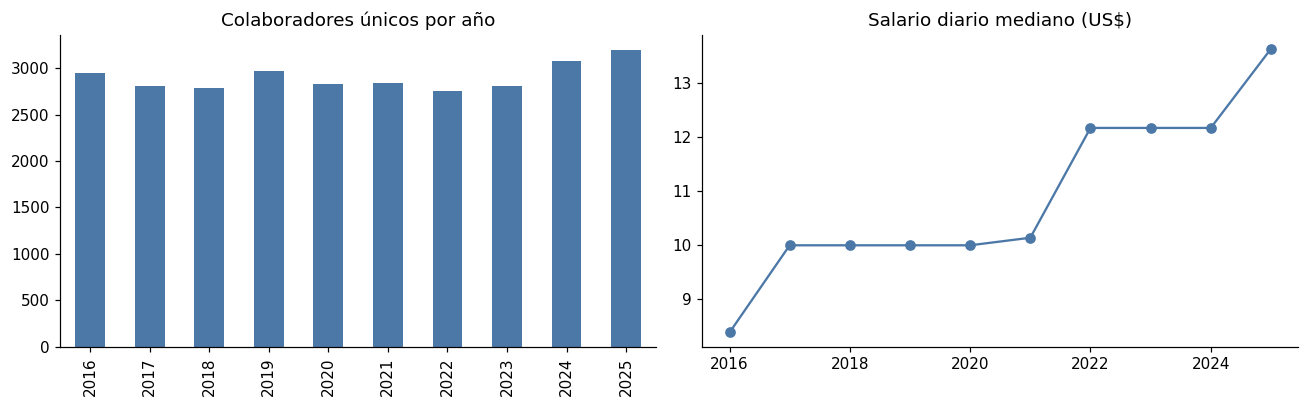

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
df.groupby("ano").empleado.nunique().plot(kind="bar", ax=ax[0], color="#4C78A8")
ax[0].set_title("Colaboradores únicos por año"); ax[0].set_xlabel("")
normal.assign(sd=normal.dias_valor / normal.dias_trabajados.replace(0, np.nan)).groupby("ano").sd.median().plot(ax=ax[1], marker="o", color="#4C78A8")
ax[1].set_title("Salario diario mediano (US$)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

**Hallazgos de calidad de datos**

| Problema | Tratamiento |
|---|---|
| Registros duplicados/ajustes de la misma persona en la misma quincena | Se agregan (suma) a nivel persona‑mes |
| `numero` no es un identificador estable | Se descarta como variable |
| `INDEMNIZACION` no siempre significa salida (renovación de contrato) | No se usa como target; se usa como variable de **renovación** con 3 meses de rezago para evitar fuga de información |
| Huecos cortos (1–2 meses) en la planilla de una persona | No se cuentan como salida; sí cuentan los huecos ≥ 3 meses (nueva relación laboral = *reingreso*) |
| Datos de 2025 terminan en diciembre: no se sabe si quienes “salieron” al final realmente se fueron (censura) | Solo se etiquetan meses hasta jun‑2025 |
| Días con salario 0 / meses sin pago dentro de una relación | Salario diario se arrastra del último valor válido; el mes se marca como inactivo |
| Planillas especiales (aguinaldo, complementos) mezcladas con la normal | Se separan; la NORMAL define actividad, las demás generan variables auxiliares |

## 4. Construcción del dataset analítico

1. Agregar la planilla NORMAL a nivel **persona‑mes**.
2. Detectar **episodios laborales** (una nueva relación inicia si la persona estuvo ausente ≥ 3 meses).
3. Crear una grilla mensual continua por episodio y calcular variables con información **disponible al cierre del mes _t_** (ventanas móviles hacia atrás).
4. Crear el target `rotacion_3m`.

In [5]:
T0 = time.time()
df["t"] = (df.ano - 2016) * 12 + df.mes - 1          # índice mensual 0..119
MAX_T = df.t.max()
NUM = ["dias_trabajados", "dias_valor", "horas_extras", "horas_valor", "nocturnidad", "bonificacion",
       "vacacion", "v_isss", "v_afp", "v_renta_1", "otros_descuentos"]

normal = df[df.tipo_planilla == 1]
m = normal.groupby(["empleado", "t"])[NUM].sum()
m["n_registros"] = normal.groupby(["empleado", "t"]).size()
m = m.reset_index().sort_values(["empleado", "t"])

# planillas auxiliares
ev  = df[df.tipo_planilla == 6].groupby(["empleado", "t"]).dias_trabajados.sum().rename("dias_eventual")
co  = df[df.tipo_planilla.isin([7, 9])].groupby(["empleado", "t"]).size().rename("n_complemento")
ind = df[df.tipo_planilla == 5].groupby(["empleado", "t"]).size().rename("n_indemn")

# episodios laborales
gap = m.groupby("empleado").t.diff()
m["episodio"] = (gap.isna() | (gap >= 4)).astype(int).groupby(m.empleado).cumsum()
ep = m.groupby(["empleado", "episodio"]).t.agg(inicio="min", fin="max").reset_index()
print("Episodios laborales:", len(ep), "| Personas con reingreso:", (ep.groupby("empleado").size() > 1).sum())

# grilla mensual continua
rows = [(e, k, tt) for e, k, a, b in ep.itertuples(index=False) for tt in range(a, b + 1)]
g = pd.DataFrame(rows, columns=["empleado", "episodio", "t"])
g = g.merge(m.drop(columns="episodio"), on=["empleado", "t"], how="left").merge(ep, on=["empleado", "episodio"])
g["activo"] = g.dias_trabajados.notna().astype(int)
g[NUM + ["n_registros"]] = g[NUM + ["n_registros"]].fillna(0)
g = g.join(ev, on=["empleado", "t"]).join(co, on=["empleado", "t"]).join(ind, on=["empleado", "t"])
g[["dias_eventual", "n_complemento", "n_indemn"]] = g[["dias_eventual", "n_complemento", "n_indemn"]].fillna(0)
print("Grilla persona-mes:", g.shape)

Episodios laborales: 9515 | Personas con reingreso: 696


Grilla persona-mes: (238906, 21)


In [6]:
grp = g.groupby(["empleado", "episodio"], sort=False)
def roll(col, w, f="mean"):
    return grp[col].transform(lambda s: getattr(s.rolling(w, min_periods=1), f)())

# --- variables básicas ---
g["salario_diario"] = g.dias_valor / g.dias_trabajados.where(g.dias_trabajados > 0)
g["salario_diario"] = grp.salario_diario.ffill()
g["antiguedad_meses"] = g.t - g.inicio
g["mes"] = g.t % 12 + 1
g["sin_afp"] = (g.v_afp == 0).astype(int)

# --- variables ampliadas ---
g["n_episodio"] = g.episodio - 1
g["reingreso"] = (g.episodio > 1).astype(int)
g["ingreso_mes"] = g.dias_valor + g.horas_valor + g.nocturnidad + g.bonificacion + g.vacacion
g["ratio_descuentos"] = g.otros_descuentos / g.ingreso_mes.replace(0, np.nan)
for w in (3, 6):
    g[f"dias_prom_{w}m"]  = roll("dias_trabajados", w)
    g[f"he_prom_{w}m"]    = roll("horas_extras", w)
    g[f"noct_prom_{w}m"]  = roll("nocturnidad", w)
    g[f"desc_prom_{w}m"]  = roll("otros_descuentos", w)
    g[f"activo_{w}m"]     = roll("activo", w)
g["dias_tendencia"] = g.dias_trabajados - g.dias_prom_6m
g["he_tendencia"]   = g.horas_extras - g.he_prom_6m
g["vacacion_12m"]   = roll("vacacion", 12, "sum")
g["bonif_12m"]      = roll("bonificacion", 12, "sum")
g["eventual_12m"]   = roll("dias_eventual", 12, "sum")
g["complemento_6m"] = roll("n_complemento", 6, "sum")
sal12 = grp.salario_diario.shift(12)
g["var_salario_12m"] = (g.salario_diario / sal12 - 1).replace([np.inf, -np.inf], np.nan)
g["sal_rel_mes"] = g.salario_diario / g.groupby("t").salario_diario.transform("median")
cambio = (g.salario_diario.round(2) != grp.salario_diario.shift().round(2)).groupby([g.empleado, g.episodio]).cumsum()
g["meses_desde_cambio_sal"] = g.groupby(["empleado", "episodio", cambio], sort=False).cumcount()
# renovaciones de contrato (indemnización pagada) con 3 meses de rezago -> sin fuga de información
g["indemn_lag3"] = grp.n_indemn.shift(3).fillna(0)
g["renovaciones"] = g.groupby(["empleado", "episodio"], sort=False).indemn_lag3.cumsum()
ult = g.t.where(g.indemn_lag3 > 0).groupby([g.empleado, g.episodio]).ffill()
g["meses_desde_renov"] = (g.t - ult).fillna(g.antiguedad_meses + 3) - 3

# --- target ---
g["meses_a_salida"] = g.fin - g.t
data = g[(g.activo == 1) & (g.t < g.fin) & (g.t <= MAX_T - 6)].copy()
data["rotacion_3m"] = (data.meses_a_salida <= 3).astype(int)
data["ano"] = data.t // 12 + 2016
print(f"Dataset analítico: {data.shape[0]:,} filas persona-mes | tasa de rotación a 3 meses: {data.rotacion_3m.mean():.1%} | {time.time()-T0:.0f}s")

Dataset analítico: 217,174 filas persona-mes | tasa de rotación a 3 meses: 8.0% | 12s


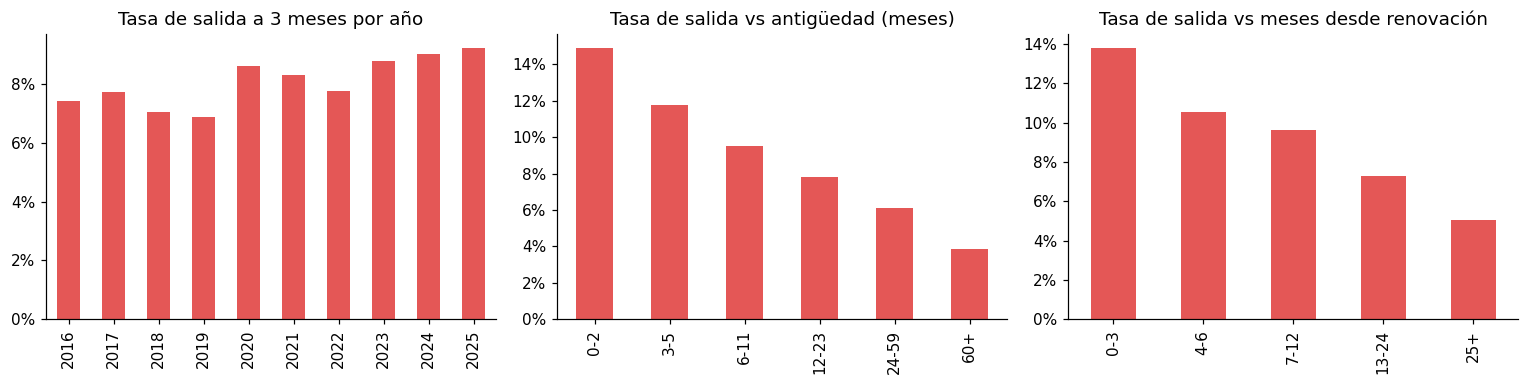

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
data.groupby("ano").rotacion_3m.mean().plot(kind="bar", ax=ax[0], color="#E45756"); ax[0].set_title("Tasa de salida a 3 meses por año"); ax[0].set_xlabel("")
cortes = [-1, 2, 5, 11, 23, 59, 200]; etiq = ["0-2", "3-5", "6-11", "12-23", "24-59", "60+"]
data.groupby(pd.cut(data.antiguedad_meses, cortes, labels=etiq)).rotacion_3m.mean().plot(kind="bar", ax=ax[1], color="#E45756")
ax[1].set_title("Tasa de salida vs antigüedad (meses)"); ax[1].set_xlabel("")
cortes = [-99, 3, 6, 12, 24, 200]; etiq = ["0-3", "4-6", "7-12", "13-24", "25+"]
data.groupby(pd.cut(data.meses_desde_renov, cortes, labels=etiq)).rotacion_3m.mean().plot(kind="bar", ax=ax[2], color="#E45756")
ax[2].set_title("Tasa de salida vs meses desde renovación"); ax[2].set_xlabel("")
for a in ax: a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

## 5. Preprocesamiento

- **Agregación y alineación temporal:** de quincenas a meses; todas las variables usan solo información pasada (ventanas móviles hacia atrás) → **sin fuga de información**.
- **Imputación:** salario diario sin pago → último valor válido; variaciones sin historia (p. ej. `var_salario_12m` en el primer año) → mediana del entrenamiento (regresión logística) o valor faltante nativo (Gradient Boosting).
- **Escalado:** `StandardScaler` para la regresión logística (sensible a escalas); no necesario en árboles.
- **Desbalance de clases** (~8 % positivos): `class_weight="balanced"` y umbral de decisión ajustado en validación en vez de 0.5.
- **Partición temporal** (no aleatoria, para simular uso real): entrenamiento 2016–2021, validación 2022, prueba 2023–jun 2025.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_fscore_support,
                             precision_recall_curve, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

BASICAS = ["antiguedad_meses", "dias_trabajados", "salario_diario", "horas_extras", "nocturnidad",
           "otros_descuentos", "sin_afp", "mes"]
AMPLIADAS = BASICAS + ["n_episodio", "reingreso", "bonificacion", "vacacion", "v_renta_1", "n_registros",
    "ratio_descuentos", "dias_prom_3m", "dias_prom_6m", "he_prom_3m", "he_prom_6m", "noct_prom_3m", "noct_prom_6m",
    "desc_prom_3m", "desc_prom_6m", "activo_3m", "activo_6m", "dias_tendencia", "he_tendencia", "vacacion_12m",
    "bonif_12m", "eventual_12m", "complemento_6m", "var_salario_12m", "sal_rel_mes", "meses_desde_cambio_sal",
    "renovaciones", "meses_desde_renov"]
Y = "rotacion_3m"

train = data[data.ano <= 2021]; valid = data[data.ano == 2022]; test = data[data.ano >= 2023]
for n, d in [("Entrenamiento", train), ("Validación", valid), ("Prueba", test)]:
    print(f"{n:14s} {len(d):7,} filas | positivos {d[Y].mean():.1%}")

def umbral_f1(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / (pr + rc + 1e-9)
    return th[f1[:-1].argmax()]

def evaluar(nombre, y, p, thr):
    yhat = (p >= thr).astype(int)
    P, R, F, _ = precision_recall_fscore_support(y, yhat, average="binary", zero_division=0)
    top = np.argsort(-p)[: int(len(p) * 0.10)]
    return {"modelo": nombre, "ROC_AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p),
            "precision": P, "recall": R, "F1": F, "umbral": thr,
            "captura_top10%": y.values[top].sum() / y.sum()}

resultados, probs = [], {}

Entrenamiento  135,282 filas | positivos 7.7%
Validación      22,174 filas | positivos 7.7%
Prueba          59,718 filas | positivos 9.0%


## 6. Iteración 1 — Regresión logística (línea base)

Modelo simple, interpretable y rápido; sirve como referencia. Usa solo las **8 variables básicas** del mes actual.

In [9]:
it1 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                    LogisticRegression(class_weight="balanced", max_iter=2000))
it1.fit(train[BASICAS], train[Y])
thr1 = umbral_f1(valid[Y], it1.predict_proba(valid[BASICAS])[:, 1])
probs["Iteración 1: Logística (básicas)"] = p1 = it1.predict_proba(test[BASICAS])[:, 1]
resultados.append(evaluar("Iteración 1: Logística (básicas)", test[Y], p1, thr1))
pd.DataFrame(resultados).round(3)

,modelo,ROC_AUC,PR_AUC,precision,recall,F1,umbral,captura_top10%
0,Iteración 1: Logística (básicas),0.676,0.162,0.16,0.492,0.242,0.545,0.21


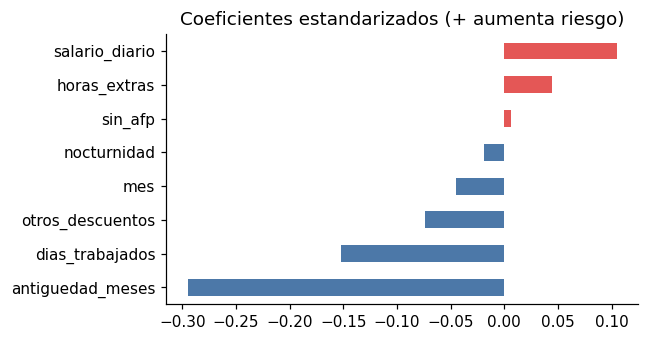

In [10]:
coef = pd.Series(it1[-1].coef_[0], index=BASICAS).sort_values()
coef.plot(kind="barh", figsize=(6, 3.2), color=np.where(coef > 0, "#E45756", "#4C78A8"))
plt.title("Coeficientes estandarizados (+ aumenta riesgo)"); plt.tight_layout(); plt.show()

### Métricas utilizadas
- **ROC‑AUC:** probabilidad de que el modelo asigne mayor riesgo a alguien que se va que a alguien que se queda (0.5 = azar, 1 = perfecto).
- **PR‑AUC (precisión promedio):** más informativa con clases desbalanceadas; la referencia del azar es la tasa de positivos (~9 % en prueba).
- **Precisión:** de los marcados en riesgo, qué % realmente se fue.
- **Recall (sensibilidad):** de los que se fueron, qué % fue detectado.
- **F1:** balance entre precisión y recall (se usa para fijar el umbral en validación).
- **Captura top 10 %:** % de las salidas reales que están dentro del 10 % de colaboradores con mayor riesgo; mide el valor operativo (si es 2× el 10 %, el modelo duplica la efectividad de una selección al azar).

## 7. Iteración 2 — Gradient Boosting + variables ampliadas + ajuste de hiperparámetros

Cambios respecto a la iteración 1:
1. **Ingeniería de variables:** tendencias de 3/6 meses, continuidad, reingresos, renovaciones de contrato, cambios salariales, salario relativo (36 variables).
2. **Modelo no lineal:** `HistGradientBoostingClassifier` (captura interacciones, maneja nulos nativamente, eficiente con 200k filas).
3. **Búsqueda de hiperparámetros** evaluada en el año de validación (2022).

Para aislar el efecto de cada cambio, también se entrena la logística con las variables ampliadas.

In [11]:
lr2 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                    LogisticRegression(class_weight="balanced", max_iter=3000))
lr2.fit(train[AMPLIADAS], train[Y])
thr = umbral_f1(valid[Y], lr2.predict_proba(valid[AMPLIADAS])[:, 1])
probs["Logística (ampliadas)"] = p = lr2.predict_proba(test[AMPLIADAS])[:, 1]
resultados.append(evaluar("Logística (ampliadas)", test[Y], p, thr))

grid = [dict(learning_rate=lr, max_leaf_nodes=hojas, min_samples_leaf=msl, l2_regularization=1.0)
        for lr in (0.03, 0.08) for hojas in (15, 31) for msl in (100, 400)]
busqueda = []
for params in grid:
    h = HistGradientBoostingClassifier(max_iter=400, early_stopping=True, validation_fraction=0.1,
                                       class_weight="balanced", random_state=42, **params)
    h.fit(train[AMPLIADAS], train[Y])
    pv = h.predict_proba(valid[AMPLIADAS])[:, 1]
    busqueda.append({**params, "iteraciones": h.n_iter_, "PR_AUC_valid": average_precision_score(valid[Y], pv),
                     "ROC_AUC_valid": roc_auc_score(valid[Y], pv)})
busqueda = pd.DataFrame(busqueda).sort_values("PR_AUC_valid", ascending=False)
display(busqueda.round(4))

,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,iteraciones,PR_AUC_valid,ROC_AUC_valid
1,0.03,15,400,1.0,400,0.1565,0.6738
6,0.08,31,100,1.0,367,0.1552,0.6669
2,0.03,31,100,1.0,400,0.1549,0.6777
3,0.03,31,400,1.0,400,0.1548,0.6735
4,0.08,15,100,1.0,335,0.1547,0.6718
7,0.08,31,400,1.0,243,0.1544,0.6716
0,0.03,15,100,1.0,400,0.1539,0.6756
5,0.08,15,400,1.0,294,0.1534,0.6694


In [12]:
mejores = busqueda.iloc[0][["learning_rate", "max_leaf_nodes", "min_samples_leaf", "l2_regularization"]].to_dict()
mejores["max_leaf_nodes"] = int(mejores["max_leaf_nodes"]); mejores["min_samples_leaf"] = int(mejores["min_samples_leaf"])
print("Mejores hiperparámetros:", mejores)
it2 = HistGradientBoostingClassifier(max_iter=400, early_stopping=True, validation_fraction=0.1,
                                     class_weight="balanced", random_state=42, **mejores)
it2.fit(train[AMPLIADAS], train[Y])
thr2 = umbral_f1(valid[Y], it2.predict_proba(valid[AMPLIADAS])[:, 1])
probs["Iteración 2: Gradient Boosting"] = p2 = it2.predict_proba(test[AMPLIADAS])[:, 1]
resultados.append(evaluar("Iteración 2: Gradient Boosting", test[Y], p2, thr2))
tabla = pd.DataFrame(resultados).set_index("modelo")
tabla.round(3)

Mejores hiperparámetros: {'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 400, 'l2_regularization': 1.0}


,ROC_AUC,PR_AUC,precision,recall,F1,umbral,captura_top10%
modelo,,,,,,,
Iteración 1: Logística (básicas),0.676,0.162,0.160,0.492,0.242,0.545,0.210
Logística (ampliadas),0.680,0.159,0.162,0.482,0.242,0.679,0.206
Iteración 2: Gradient Boosting,0.694,0.177,0.189,0.422,0.261,0.609,0.239


## 8. Comparación e interpretación

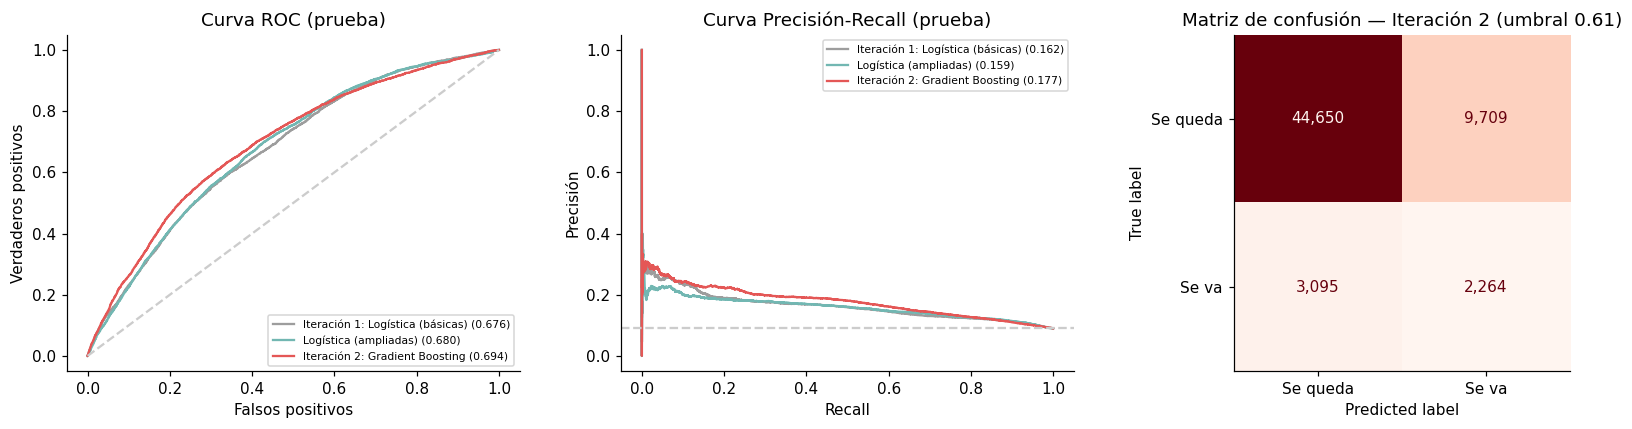

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
colores = ["#9D9D9D", "#72B7B2", "#E45756"]
for (n, p), c in zip(probs.items(), colores):
    fpr, tpr, _ = roc_curve(test[Y], p); ax[0].plot(fpr, tpr, label=f"{n} ({roc_auc_score(test[Y], p):.3f})", color=c)
    pr, rc, _ = precision_recall_curve(test[Y], p); ax[1].plot(rc, pr, label=f"{n} ({average_precision_score(test[Y], p):.3f})", color=c)
ax[0].plot([0, 1], [0, 1], "--", color="#ccc"); ax[0].set(title="Curva ROC (prueba)", xlabel="Falsos positivos", ylabel="Verdaderos positivos")
ax[1].axhline(test[Y].mean(), ls="--", color="#ccc"); ax[1].set(title="Curva Precisión-Recall (prueba)", xlabel="Recall", ylabel="Precisión")
ax[0].legend(fontsize=7, loc="lower right"); ax[1].legend(fontsize=7)
ConfusionMatrixDisplay(confusion_matrix(test[Y], (p2 >= thr2).astype(int)), display_labels=["Se queda", "Se va"]).plot(ax=ax[2], cmap="Reds", colorbar=False, values_format=",")
ax[2].set_title(f"Matriz de confusión — Iteración 2 (umbral {thr2:.2f})")
plt.tight_layout(); plt.show()

In [14]:
# Lift por decil de riesgo (iteración 2)
dec = pd.DataFrame({"y": test[Y].values, "p": p2})
dec["decil"] = pd.qcut(dec.p.rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = dec.groupby("decil").agg(colaboradores=("y", "size"), salidas=("y", "sum"), tasa=("y", "mean"))
lift["lift"] = lift.tasa / dec.y.mean()
lift["captura_acumulada"] = lift.salidas.cumsum() / dec.y.sum()
lift.round(3)

,colaboradores,salidas,tasa,lift,captura_acumulada
decil,,,,,
1,5972,1281,0.215,2.390,0.239
2,5972,978,0.164,1.825,0.422
3,5972,754,0.126,1.407,0.562
4,5971,541,0.091,1.010,0.663
5,5972,469,0.079,0.875,0.751
6,5972,391,0.065,0.730,0.824
7,5971,323,0.054,0.603,0.884
8,5972,241,0.040,0.450,0.929
9,5972,217,0.036,0.405,0.969


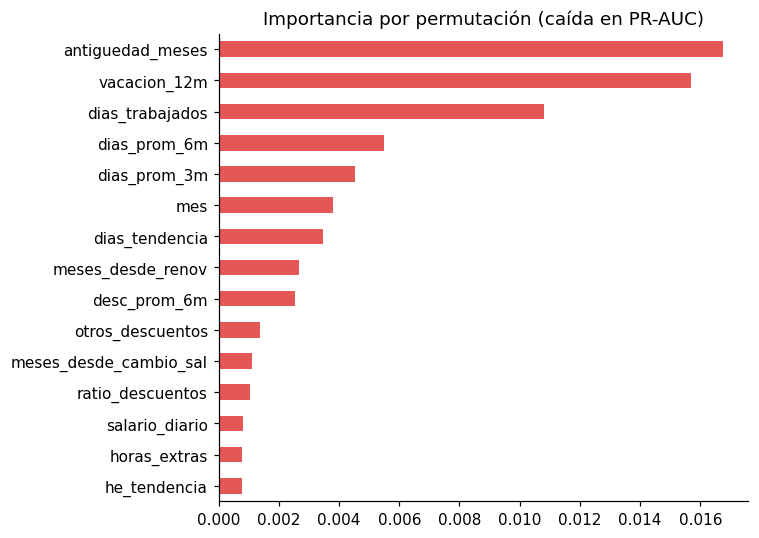

,caida_PR_AUC
antiguedad_meses,0.0167
vacacion_12m,0.0157
dias_trabajados,0.0108
dias_prom_6m,0.0055
dias_prom_3m,0.0045
mes,0.0038
dias_tendencia,0.0035
meses_desde_renov,0.0027
desc_prom_6m,0.0025
otros_descuentos,0.0014


In [15]:
from sklearn.inspection import permutation_importance
muestra = test.sample(20000, random_state=42)
imp = permutation_importance(it2, muestra[AMPLIADAS], muestra[Y], scoring="average_precision", n_repeats=3, random_state=42, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=AMPLIADAS).sort_values().tail(15)
imp.plot(kind="barh", figsize=(7, 5), color="#E45756")
plt.title("Importancia por permutación (caída en PR-AUC)"); plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(4).to_frame("caida_PR_AUC")

### Lista de riesgo para el último mes disponible
Así se usaría en la operación: se entrena con todo el historial etiquetado y se califica a todo el personal activo al cierre del último mes.

In [16]:
final = HistGradientBoostingClassifier(max_iter=400, early_stopping=True, validation_fraction=0.1,
                                       class_weight="balanced", random_state=42, **mejores)
final.fit(data[AMPLIADAS], data[Y])
actual = g[(g.t == MAX_T) & (g.activo == 1)].copy()
actual["prob_rotacion_3m"] = final.predict_proba(actual[AMPLIADAS])[:, 1]
actual["nivel_riesgo"] = pd.qcut(actual.prob_rotacion_3m.rank(method="first"), [0, .7, .9, 1], labels=["Bajo", "Medio", "Alto"])
print(f"Personal activo en {2016 + MAX_T // 12}-{MAX_T % 12 + 1:02d}: {len(actual):,}")
display(actual.nivel_riesgo.value_counts().to_frame("colaboradores"))
actual.sort_values("prob_rotacion_3m", ascending=False)[["empleado", "prob_rotacion_3m", "nivel_riesgo",
    "antiguedad_meses", "salario_diario", "dias_prom_3m", "he_prom_3m", "meses_desde_renov"]].head(15).round(3)

Personal activo en 2025-12: 2,280


,colaboradores
nivel_riesgo,
Bajo,1596
Medio,456
Alto,228


,empleado,prob_rotacion_3m,nivel_riesgo,antiguedad_meses,salario_diario,dias_prom_3m,he_prom_3m,meses_desde_renov
238425,21178,0.863,Alto,3,13.626,12.000,0.0,3.0
238522,21207,0.847,Alto,3,13.625,7.000,0.0,3.0
238747,21305,0.846,Alto,2,13.620,10.833,0.0,2.0
238853,21362,0.835,Alto,1,13.626,13.250,0.0,1.0
238902,21402,0.832,Alto,0,13.626,5.000,0.0,0.0
238729,21295,0.832,Alto,2,13.626,11.333,0.0,2.0
238893,21393,0.831,Alto,0,13.625,2.000,0.0,0.0
238889,21389,0.829,Alto,0,13.626,8.000,0.0,0.0
238866,21369,0.829,Alto,1,13.626,7.000,0.0,1.0
237900,21051,0.824,Alto,5,13.493,23.167,0.0,5.0


## 9. Respuestas a las preguntas de análisis

### 1. ¿Cuál fue el problema de negocio identificado y por qué es relevante para tu organización?
Superior Cleaning Services pierde entre **500 y 850 colaboradores por año** sobre una planilla de ~2,800–3,200 personas (rotación anual de ~20–30 %), y en 2023–2025 la tasa de salida a 3 meses subió de ~7.5 % a ~9 %. Cada salida genera costos de reclutamiento, inducción y uniformes, horas extra para cubrir vacantes y riesgo de incumplimiento con los clientes. Hoy la empresa solo se entera cuando la persona ya se fue. El problema es **anticipar qué colaboradores tienen alta probabilidad de salir en los próximos 3 meses** para que RR. HH. y supervisión puedan intervenir a tiempo y concentrar sus esfuerzos de retención.

### 2. ¿Cómo construiste el dataset y qué desafíos encontraste durante la recopilación de datos?
Se partió de **10 archivos XLS de planilla (2016–2025)**, unificados en un CSV de **513,813 registros** y **10,322 colaboradores** anonimizados. Como el sistema de planillas no registra la “fecha de baja”, el dataset de ML se construyó así:
1. Agregación de quincenas a **persona‑mes** usando solo la planilla NORMAL para definir actividad.
2. Detección de **9,515 episodios laborales** (ausencia ≥ 3 meses = nueva relación; 696 personas tienen reingresos).
3. Grilla mensual continua por episodio y cálculo de **36 variables** con información pasada (antigüedad, días, salario, horas extra, nocturnidad, descuentos, vacaciones, renovaciones, etc.).
4. Target `rotacion_3m`. Resultado: **217,174 filas persona‑mes**, 8.0 % positivas.

Desafíos: no existe un campo de baja ni de motivo de salida; la planilla de **indemnización no siempre es salida** (también se paga al renovar contratos); no hay datos demográficos, de puesto ni de cliente/sede; el campo `numero` parecía un identificador pero es un correlativo de recibo; y los datos de los últimos meses de 2025 están **censurados** (aún no se sabe si quien dejó de aparecer volverá).

### 3. ¿Qué problemas de calidad de datos identificaste y cómo los solucionaste?
- **6,077 registros repetidos** de la misma persona en la misma quincena (ajustes) → se suman al agregar por mes.
- **`numero` no es estable** (mediana de 28 valores distintos por persona) → se descartó.
- **Indemnización ambigua** (salida vs. renovación) → no se usa como target; se convierte en la variable “renovaciones de contrato” con 3 meses de rezago.
- **Huecos cortos** en la planilla (1–2 meses) → no se cuentan como salida.
- **Censura al final del periodo** → solo se etiquetan meses hasta junio de 2025.
- **Meses sin días pagados** dentro de un episodio → el salario diario se arrastra del último valor válido y el mes se marca inactivo.
- **Planillas especiales mezcladas** (aguinaldo, complementos, eventuales) → se separan y se usan como variables auxiliares.
- Se verificó que no hay nulos ni montos negativos en el archivo limpio.

### 4. ¿Qué técnicas de preprocesamiento aplicaste y por qué fueron necesarias?
- **Ingeniería de variables temporales** (promedios móviles de 3/6/12 meses, tendencias, variación salarial anual, meses desde la última renovación o cambio salarial): una sola quincena dice poco, el riesgo se ve en los cambios de comportamiento.
- **Prevención de fuga de información:** todas las variables miran solo hacia atrás, la indemnización entra con rezago de 3 meses y se excluye el último mes de cada relación (su planilla final ya revela la salida).
- **Imputación** (mediana) para variables sin historia, necesaria para la regresión logística; Gradient Boosting maneja nulos de forma nativa.
- **Estandarización** (`StandardScaler`) para la regresión logística, sensible a la escala.
- **Manejo del desbalance** (8 % positivos): `class_weight="balanced"` y **umbral optimizado por F1 en validación**, en lugar de 0.5.
- **Partición temporal** (entrenamiento 2016–2021, validación 2022, prueba 2023–jun 2025): simula el uso real (predecir el futuro con el pasado) y evita resultados optimistas de un split aleatorio.

### 5. ¿Por qué seleccionaste el modelo de Machine Learning utilizado?
- **Iteración 1 – Regresión logística:** línea base estándar para clasificación binaria; es interpretable (coeficientes = dirección del riesgo), rápida y difícil de sobreajustar.
- **Iteración 2 – `HistGradientBoostingClassifier`:** el riesgo de salida depende de **interacciones no lineales** (p. ej. poca antigüedad combinada con caída de días trabajados). Los árboles con boosting capturan estas relaciones, manejan valores faltantes, no requieren escalado, son eficientes con más de 200k filas y suelen ser el mejor modelo para datos tabulares.

### 6. ¿Qué métricas utilizaste para evaluar el desempeño del modelo y qué significan sus valores?
Resultados sobre el periodo de prueba **2023–jun 2025** (59,718 casos, 9.0 % de salidas):

| Modelo | ROC‑AUC | PR‑AUC | Precisión | Recall | F1 | Captura top 10 % |
|---|---|---|---|---|---|---|
| Iteración 1: Logística (8 variables) | 0.676 | 0.162 | 0.160 | 0.492 | 0.242 | 21.0 % |
| Logística (36 variables) | 0.680 | 0.159 | 0.162 | 0.482 | 0.242 | 20.6 % |
| **Iteración 2: Gradient Boosting** | **0.694** | **0.177** | **0.189** | 0.422 | **0.261** | **23.9 %** |

- **ROC‑AUC 0.694:** en ~69 % de los pares (uno que se va y otro que se queda), el modelo asigna más riesgo al que se va. Es una capacidad discriminativa **moderada** (0.5 = azar).
- **PR‑AUC 0.177:** casi **2 veces** la línea base del azar (0.09).
- **Precisión 0.189 / Recall 0.422:** con el umbral elegido, el modelo detecta el **42 % de las salidas**, y ~1 de cada 5 alertas corresponde a una salida real (al azar sería ~1 de cada 11).
- **Captura top 10 %:** el 10 % de colaboradores con mayor riesgo concentra el **23.9 % de las salidas** (lift = 2.4). El 30 % de mayor riesgo concentra el **56 %**.

### 7. ¿Qué conclusiones puedes extraer a partir de los resultados obtenidos?
- La **antigüedad** es el factor más fuerte: en los primeros 3 meses la tasa de salida a 3 meses es ~15 %, frente a ~4 % con más de 5 años. La retención debe enfocarse en el **onboarding** y los primeros 6 meses.
- Las variables más importantes (por permutación) son: antigüedad, **vacaciones gozadas en los últimos 12 meses** (quien llega a tomar vacaciones tiene más arraigo), **días trabajados** del mes y su promedio y tendencia (una caída de días anticipa la salida), la estacionalidad (más salidas entre diciembre y marzo), los meses desde la última renovación y los **descuentos** (préstamos/embargos).
- Las **renovaciones recientes** de contrato se asocian a más salidas (~14 % en los 3 meses siguientes a la renovación, frente a ~5 % después de 2 años).
- Solo con datos de planilla el poder predictivo es **moderado**: el modelo sirve para **priorizar**, no para afirmar con certeza quién se irá. Gran parte de las causas de salida (clima laboral, supervisor, distancia, otra oferta) no está en la planilla.

### 8. ¿Qué modificación realizaste en la segunda iteración y cómo impactó el desempeño del modelo?
Se hicieron tres cambios: (1) se pasó de 8 a **36 variables** (tendencias, continuidad, reingresos, renovaciones, cambios salariales, salario relativo); (2) se cambió a un modelo **no lineal** (Gradient Boosting); (3) se hizo una **búsqueda de hiperparámetros** (8 combinaciones evaluadas en 2022; la mejor fue learning_rate = 0.03, max_leaf_nodes = 15, min_samples_leaf = 400).

Impacto en prueba: ROC‑AUC 0.676 → **0.694**, PR‑AUC 0.162 → **0.177** (+9 %), precisión 0.160 → **0.189** (+18 %), F1 0.242 → **0.261**, captura top 10 % 21.0 % → **23.9 %** (+14 %). El recall bajó (0.49 → 0.42) porque el umbral óptimo es más exigente: menos alertas, pero más certeras. La comparación aislada muestra que **agregar variables a la logística casi no ayudó** (0.676 → 0.680): la mejora proviene de combinar las nuevas variables con un modelo capaz de aprovechar sus interacciones.

### 9. ¿Recomendarías implementar la solución en tu organización? Justifica tu respuesta con evidencia.
**Sí, como piloto de alerta temprana para priorizar acciones de retención, no como herramienta de decisión automática.**
- Evidencia a favor: en datos que el modelo nunca vio (2023–2025), el 10 % de mayor riesgo concentra **2.4 veces** más salidas que una selección al azar, y el 30 % de mayor riesgo concentra el **56 %** de las salidas. Con ~2,300 colaboradores activos, una lista mensual de ~230 personas de riesgo “Alto” es manejable para RR. HH. y supervisores.
- El modelo usa datos que la empresa ya genera cada quincena: el costo de operarlo es mínimo y se puede reentrenar cada mes.
- Limitaciones: la precisión es moderada (~19 %), así que muchas alertas no terminarán en salida. Por eso las acciones deben ser **de bajo costo y positivas** (entrevista de seguimiento, revisión de turno o ubicación, reconocimiento), nunca punitivas ni discriminatorias.
- Propuesta: un piloto de 6 meses en un grupo de sedes, con un grupo de control, midiendo si la tasa de salida del grupo intervenido baja frente al control antes de escalarlo.

### 10. ¿Qué aprendiste durante el desarrollo de este proyecto y cómo podrías mejorar la solución en una siguiente versión?
**Aprendizajes:**
- Definir bien el target es la parte más difícil: sin fecha de baja hubo que inferir la salida. El conocimiento del negocio fue clave, por ejemplo que la indemnización también se paga al **renovar** contratos.
- Cuidar la **fuga de información** y usar una **partición temporal** da métricas más bajas, pero honestas.
- Con clases desbalanceadas, la exactitud engaña: PR‑AUC, recall y lift por decil reflejan mejor el valor real.
- Un modelo más complejo solo ayuda si las variables aportan información nueva.

**Mejoras para la siguiente versión:**
- Incorporar datos fuera de planilla: puesto, sede/cliente, supervisor, turno, distancia al trabajo, edad, ausentismo y amonestaciones, motivo de salida (renuncia vs. despido, para modelar solo la rotación voluntaria) y encuestas de clima.
- Calcular la tasa de rotación por sede/cliente como variable de contexto.
- Probar modelos de **supervivencia** (tiempo hasta la salida) y otros algoritmos (LightGBM/XGBoost), con validación temporal móvil.
- Calibrar probabilidades y explicar cada predicción con **SHAP**, para que el supervisor sepa *por qué* alguien está en riesgo.
- Automatizar el reentrenamiento mensual, con un tablero de riesgo y monitoreo del desempeño.